# MEMBER3 - Outlier Handling

**Dataset:** Ames Housing (`train.csv`, 1,460 houses, 79 features + `SalePrice`)  
**Task:** predict the sale price of a house (regression).  
Run this notebook from the `notebooks/` folder so the `../data/raw/` paths resolve.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style('whitegrid')
%matplotlib inline

df = pd.read_csv('../data/raw/train.csv')
test = pd.read_csv('../data/raw/test.csv')
print('train:', df.shape, '| test:', test.shape)
df.head()

train: (1460, 81) | test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1. Skewed variables and the target

In [2]:
num = df.select_dtypes(include='number').drop(columns=['Id', 'MSSubClass'])
skew = num.skew().sort_values(ascending=False)
print('SalePrice skewness raw:', round(df['SalePrice'].skew(), 2), '| after log1p:', round(np.log1p(df['SalePrice']).skew(), 2))
skew.head(8).round(2)

SalePrice skewness raw: 1.88 | after log1p: 0.12


MiscVal         24.48
PoolArea        14.83
LotArea         12.21
3SsnPorch       10.30
LowQualFinSF     9.01
KitchenAbvGr     4.49
BsmtFinSF2       4.26
ScreenPorch      4.12
dtype: float64

## 2. Candidate A - sequential IQR row filter (rejected)

Remove any house outside `Q1 - 1.5*IQR ... Q3 + 1.5*IQR` on five size columns, one after another.

In [3]:
iqr_cols = ['LotArea', 'GrLivArea', 'TotalBsmtSF', '1stFlrSF', 'LotFrontage']
df_iqr = df.copy()
for c in iqr_cols:
    q1, q3 = df_iqr[c].quantile([0.25, 0.75]); iqr = q3 - q1
    df_iqr = df_iqr[df_iqr[c].isna() | ((df_iqr[c] >= q1 - 1.5 * iqr) & (df_iqr[c] <= q3 + 1.5 * iqr))]
print('Rows:', len(df), '->', len(df_iqr), f'({len(df) - len(df_iqr)} removed, {(len(df) - len(df_iqr)) / len(df):.1%})')
print('Mean price  :', round(df['SalePrice'].mean()), '->', round(df_iqr['SalePrice'].mean()))
print('Median price:', round(df['SalePrice'].median()), '->', round(df_iqr['SalePrice'].median()))
print('Houses above $400k:', (df['SalePrice'] > 400000).sum(), '->', (df_iqr['SalePrice'] > 400000).sum())

Rows: 1460 -> 1251 (209 removed, 14.3%)
Mean price  : 180921 -> 173398
Median price: 163000 -> 159950
Houses above $400k: 28 -> 3


## 3. Candidate B - targeted removal of 2 documented extreme rows + log transform (chosen)

Four houses have `GrLivArea` > 4,000 sq ft. Two of them sold for very high prices (consistent with their size) and are kept. The other two (Ids 524 and 1299) are *partial sales* of huge houses priced below $200k, which contradict the size-price relationship and are treated as data anomalies. The target is log-transformed, and the long right tails of the other skewed fields are compressed with `log1p`.

In [4]:
big = df[df['GrLivArea'] > 4000][['Id', 'GrLivArea', 'SalePrice', 'SaleCondition']]
display(big)
extreme = (df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)
df_final = df[~extreme].copy()
df_final['SalePrice_log'] = np.log1p(df_final['SalePrice'])
skewed = [c for c in num.columns if c != 'SalePrice' and abs(df[c].skew()) > 0.75 and df[c].min() >= 0]
for c in skewed: df_final[c] = np.log1p(df_final[c])
print('Rows removed:', int(extreme.sum()), '| rows kept:', len(df_final))
print('Columns log1p-transformed:', len(skewed))
print('Mean price after targeted removal:', round(df_final['SalePrice'].mean()))

,Id,GrLivArea,SalePrice,SaleCondition
523,524,4676,184750,Partial
691,692,4316,755000,Normal
1182,1183,4476,745000,Abnorml
1298,1299,5642,160000,Partial


Rows removed: 2 | rows kept: 1458
Columns log1p-transformed: 20
Mean price after targeted removal: 180933


## 4. EDA visualizations

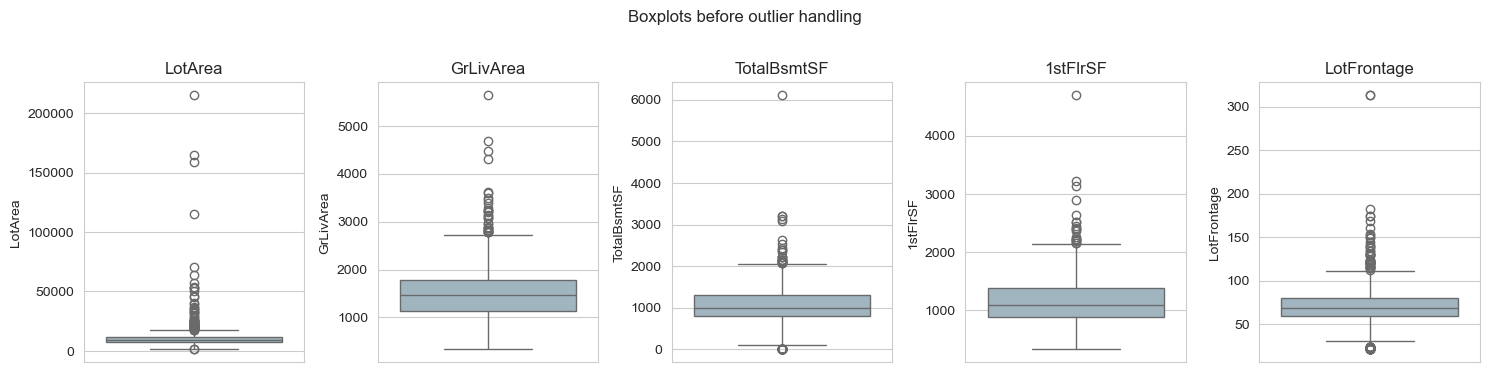

In [5]:
os.makedirs('../results/eda_visualizations/OutlierRemoval', exist_ok=True)
fig, axes = plt.subplots(1, 5, figsize=(15, 3.6))
for ax, c in zip(axes, iqr_cols):
    sns.boxplot(y=df[c], ax=ax, color='#9CB7C5'); ax.set_title(c)
fig.suptitle('Boxplots before outlier handling', y=1.02)
plt.tight_layout()
plt.savefig('../results/eda_visualizations/OutlierRemoval/boxplot_before.png', dpi=120)
plt.show()

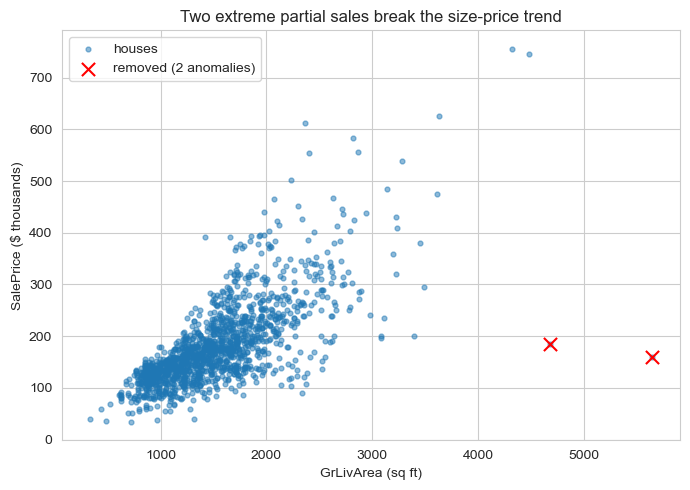

In [6]:
plt.figure(figsize=(7, 5))
plt.scatter(df['GrLivArea'], df['SalePrice'] / 1000, s=12, alpha=0.5, label='houses')
plt.scatter(df.loc[extreme, 'GrLivArea'], df.loc[extreme, 'SalePrice'] / 1000, s=90, color='red', marker='x', label='removed (2 anomalies)')
plt.xlabel('GrLivArea (sq ft)'); plt.ylabel('SalePrice ($ thousands)'); plt.legend()
plt.title('Two extreme partial sales break the size-price trend')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/OutlierRemoval/grlivarea_scatter.png', dpi=120)
plt.show()

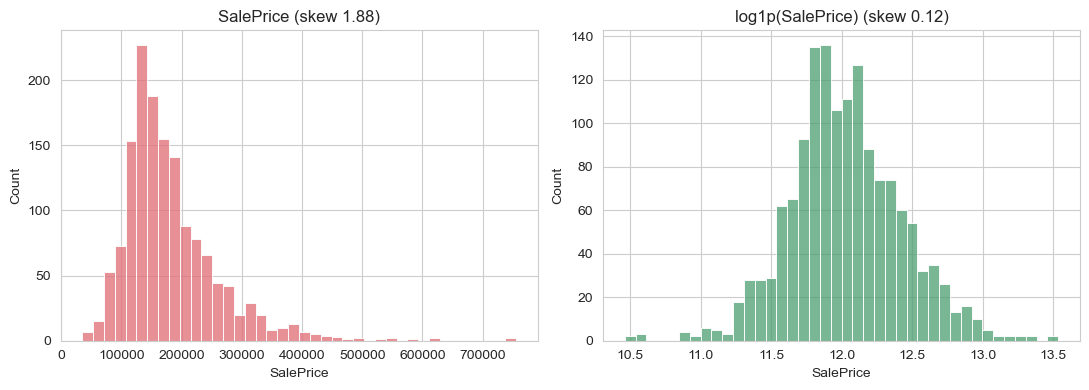

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['SalePrice'], bins=40, ax=axes[0], color='#E06C75'); axes[0].set_title(f"SalePrice (skew {df['SalePrice'].skew():.2f})")
sns.histplot(np.log1p(df['SalePrice']), bins=40, ax=axes[1], color='#4C9F70'); axes[1].set_title(f"log1p(SalePrice) (skew {np.log1p(df['SalePrice']).skew():.2f})")
plt.tight_layout()
plt.savefig('../results/eda_visualizations/OutlierRemoval/saleprice_log_transform.png', dpi=120)
plt.show()

In [8]:
os.makedirs('../results/outputs', exist_ok=True)
summary = pd.DataFrame([
    ['original', len(df), df['SalePrice'].mean(), df['SalePrice'].median(), (df['SalePrice'] > 400000).sum()],
    ['rejected_sequential_iqr_filter', len(df_iqr), df_iqr['SalePrice'].mean(), df_iqr['SalePrice'].median(), (df_iqr['SalePrice'] > 400000).sum()],
    ['final_targeted_removal_plus_log', len(df_final), df_final['SalePrice'].mean(), df_final['SalePrice'].median(), (df_final['SalePrice'] > 400000).sum()],
], columns=['stage', 'rows', 'mean_price', 'median_price', 'houses_over_400k']).round(0)
summary.to_csv('../results/outputs/outlier_handling_summary.csv', index=False)
summary

,stage,rows,mean_price,median_price,houses_over_400k
0,original,1460,180921.0,163000.0,28
1,rejected_sequential_iqr_filter,1251,173398.0,159950.0,3
2,final_targeted_removal_plus_log,1458,180933.0,163000.0,28


### Interpretation

The sequential IQR filter removes **209 of 1,460 houses (14.3 %)** and, because it targets large lots and floor areas, it deletes mostly the *expensive* homes: the mean price drops from about $180.9k to $173.4k and the number of houses over $400k falls sharply. That distorts the very price range the model must predict, and the test file contains similar large houses, so the filter is rejected. Instead the project keeps genuine large/expensive houses, removes only the **two documented anomalies** (huge houses with tiny prices), and applies `log1p` to the target and to skewed numeric fields. In the model notebooks the two rows are dropped from the **training split only**, never from the hold-out set.